In [1]:
import pandas as pd
import pdb
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mode
from sklearn.model_selection import train_test_split


In [2]:
def get_available_device():
    if torch.cuda.is_available():
        return "cuda"
    elif torch.backends.mps.is_available():
        return "mps"
    else:
        return "cpu"
    
CONFIG = {
    "seed": 42,
    "epochs": 12, # 42, ~MAX 20 hours of training
    "train_batch_size": 16,
    "valid_batch_size": 64,
    "learning_rate": 5e-5,
    "scheduler": 'CosineAnnealingLR',
    "min_lr": 5e-7,
    "T_max": 12,
    "weight_decay": 1e-6,
    "fold" : 0,
    "n_fold": 5,
    "n_accumulate": 4,
    "device": 'cpu',
}

# Read the parquet file and get rough statistics

In [3]:
df = pd.read_pickle("../data/enveda_chemist_preprocessed.pkl")
df.shape

(1667, 30)

In [4]:
df.head(10)

,ground_truth_smiles,predicted_smiles,ground_truth_inchikey14,predicted_inchikey14,ground_truth_formula,predicted_formula,annotator_name,unable_to_assess,not_close_match,close_match,...,ground_truth_embeddings,predicted_embeddings,ground_truth_mol,predicted_mol,ground_truth_ECFP,predicted_ECFP,predicted_grover_fp,ground_truth_grover_fp,ground_truth_graph_emb,predicted_graph_emb
7,CC1(C)C=Cc2c(ccc3c2[N+]([O-])=C2C(C)(C)C4CC56C...,CC7(C)C=Cc1c(ccc2c1N=C6C2(O)CC45N=C(O)C3(CCCN3...,WZHCMAFZIFECCV,PYHKDROAWLAEDE,C52H54N6O7,C26H29N3O4,0,1,0,0,...,"[[0.5249046, 0.25463453, 1.1345551, 0.9046077,...","[[0.96212196, 0.038501173, 0.9624641, 0.423108...",<rdkit.Chem.rdchem.Mol object at 0x30ff9fc70>,<rdkit.Chem.rdchem.Mol object at 0x310557450>,"[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[-0.036697034, -0.11841076, 0.42434365, -0.088...","[0.028250804, -0.076480605, 0.2331932, -0.2197...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ..."
8,CC1(C)C=Cc2c(ccc3c2[N+]([O-])=C2C(C)(C)C4CC56C...,CC7(C)C=Cc1c(ccc2c1N=C6C2(O)CC45N=C(O)C3(CCCN3...,WZHCMAFZIFECCV,PYHKDROAWLAEDE,C52H54N6O7,C26H29N3O4,1,1,0,0,...,"[[0.5249046, 0.25463453, 1.1345551, 0.9046077,...","[[0.96212196, 0.038501173, 0.9624641, 0.423108...",<rdkit.Chem.rdchem.Mol object at 0x17f7ab4a0>,<rdkit.Chem.rdchem.Mol object at 0x310557540>,"[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[-0.036697034, -0.11841076, 0.42434365, -0.088...","[0.028250804, -0.076480605, 0.2331932, -0.2197...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ..."
9,CC1(C)C=Cc2c(ccc3c2[N+]([O-])=C2C(C)(C)C4CC56C...,CC7(C)C=Cc1c(ccc2c1N=C6C2(O)CC45N=C(O)C3(CCCN3...,WZHCMAFZIFECCV,PYHKDROAWLAEDE,C52H54N6O7,C26H29N3O4,2,1,0,0,...,"[[0.5249046, 0.25463453, 1.1345551, 0.9046077,...","[[0.96212196, 0.038501173, 0.9624641, 0.423108...",<rdkit.Chem.rdchem.Mol object at 0x17f7ab4f0>,<rdkit.Chem.rdchem.Mol object at 0x310557590>,"[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[-0.036697034, -0.11841076, 0.42434365, -0.088...","[0.028250804, -0.076480605, 0.2331932, -0.2197...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ..."
10,CC1(C)C=Cc2c(ccc3c2[N+]([O-])=C2C(C)(C)C4CC56C...,CC7(C)C=Cc1c(ccc2c1N=C6C2(O)CC45N=C(O)C3(CCCN3...,WZHCMAFZIFECCV,PYHKDROAWLAEDE,C52H54N6O7,C26H29N3O4,3,0,1,0,...,"[[0.5249046, 0.25463453, 1.1345551, 0.9046077,...","[[0.96212196, 0.038501173, 0.9624641, 0.423108...",<rdkit.Chem.rdchem.Mol object at 0x17f7ab540>,<rdkit.Chem.rdchem.Mol object at 0x3105575e0>,"[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[-0.036697034, -0.11841076, 0.42434365, -0.088...","[0.028250804, -0.076480605, 0.2331932, -0.2197...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ..."
11,CC1(C)C=Cc2c(ccc3c2[N+]([O-])=C2C(C)(C)C4CC56C...,CC7(C)C=Cc1c(ccc2c1N=C6C2(O)CC45N=C(O)C3(CCCN3...,WZHCMAFZIFECCV,PYHKDROAWLAEDE,C52H54N6O7,C26H29N3O4,4,1,0,0,...,"[[0.5249046, 0.25463453, 1.1345551, 0.9046077,...","[[0.96212196, 0.038501173, 0.9624641, 0.423108...",<rdkit.Chem.rdchem.Mol object at 0x17f7ab590>,<rdkit.Chem.rdchem.Mol object at 0x310557630>,"[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ...","[-0.036697034, -0.11841076, 0.42434365, -0.088...","[0.028250804, -0.076480605, 0.2331932, -0.2197...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ...","[(x, [tensor([1.0000, 0.0000, 0.0000, 0.0000, ..."
12,COc1ccc(OCCCS(=O)(=O)O)cc1,CC=CC(=O)OCc1ccc(S(=O)(=O)O)cc1,XIQZEFWKVAYYEU,DBFPTOZSTUTGPV,C10H14O5S,C11H12O5S,0,0,1,0,...,"[[0.042767983, 0.43244871, 0.43164873, 0.21183...","[[0.65620965, 0.46203485, 0.3969433, 0.1169092...",<rdkit.Chem.rdchem.

# Binarize

In [ ]:
# 

# Remove duplicate pair of SMILES through majority voting

In [11]:

# Step 1: Group by the SMILES pairs
rating_columns = ['unable_to_assess', 'not_close_match', 'close_match', 'near_exact_match', 'exact_match', 'good_enough_for_prioritization']

df_grouped = df.groupby(['ground_truth_smiles', 'predicted_smiles'], as_index=False).agg(lambda x: list(x))

# Step 2: Majority voting on the rating columns
for col in rating_columns:
    # Find the mode (most common value)
    df_grouped[col] = df_grouped[col].apply(lambda x: mode(x).mode[0])

# Step 3: Handle ties by picking the first occurrence or using another logic
# Here we assume that mode will handle ties by returning the first mode found

# Step 4: numpy arrays for the embeddings have been grouped into lists. index the
# first array of the list
    
df_grouped['ground_truth_embeddings'] = df_grouped['ground_truth_embeddings'].apply(lambda x: x[0])
df_grouped['predicted_embeddings'] = df_grouped['predicted_embeddings'].apply(lambda x: x[0])

df_grouped['ground_truth_mol'] = df_grouped['ground_truth_embeddings'].apply(lambda x: x[0])
df_grouped['predicted_mol'] = df_grouped['predicted_embeddings'].apply(lambda x: x[0])

df_grouped['ground_truth_ECFP'] = df_grouped['ground_truth_embeddings'].apply(lambda x: x[0])
df_grouped['predicted_ECFP'] = df_grouped['predicted_embeddings'].apply(lambda x: x[0])

df_grouped['ground_truth_grover_fp'] = df_grouped['ground_truth_embeddings'].apply(lambda x: x[0])
df_grouped['predicted_grover_fp'] = df_grouped['predicted_embeddings'].apply(lambda x: x[0])

df_grouped['ground_truth_graph_emb'] = df_grouped['ground_truth_embeddings'].apply(lambda x: x[0])
df_grouped['predicted_graph_emb'] = df_grouped['predicted_embeddings'].apply(lambda x: x[0])

df_grouped.shape


/var/folders/lc/2w4cj8jj4gv7hqz913wc9b4m0000gn/T/ipykernel_81778/3023540951.py:9: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  df_grouped[col] = df_grouped[col].apply(lambda x: mode(x).mode[0])
/var/folders/lc/2w4cj8jj4gv7hqz913wc9b4m0000gn/T/ipykernel_81778/3023540951.py:9: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted

(436, 30)

In [22]:
df_grouped.to_pickle('../data/enveda_remove_duplicates_preprocessed.pkl')
df_grouped.head(10)

,ground_truth_smiles,predicted_smiles,ground_truth_inchikey14,predicted_inchikey14,ground_truth_formula,predicted_formula,annotator_name,unable_to_assess,not_close_match,close_match,...,ground_truth_embeddings,predicted_embeddings,ground_truth_mol,predicted_mol,ground_truth_ECFP,predicted_ECFP,predicted_grover_fp,ground_truth_grover_fp,ground_truth_graph_emb,predicted_graph_emb
0,Brc1ccc(-c2cn3ccncc3n2)cc1,Brc3cn2cc(-c1ccccc1)ncc2n3,"[[SRVMTZOOFHVUJN, SRVMTZOOFHVUJN, SRVMTZOOFHVU...","[[XBVDVRMQYSQFSP, XBVDVRMQYSQFSP, XBVDVRMQYSQF...","[[C12H8BrN3, C12H8BrN3, C12H8BrN3]]","[[C12H8BrN3, C12H8BrN3, C12H8BrN3]]","[[0, 2, 4]]",0,0,0,...,"[[0.0472339, 0.04043176, 0.813079, -0.10981892...","[[0.2877463, 0.12259397, 0.69546384, 0.1167923...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.2877463, 0.12259397, 0.69546384, 0.11679233...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.2877463, 0.12259397, 0.69546384, 0.11679233...","[0.2877463, 0.12259397, 0.69546384, 0.11679233...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.2877463, 0.12259397, 0.69546384, 0.11679233..."
1,C1=CCC(C2OCC3(CO2)COC(C2CC=CCC2)OC3)CC1,C3=CCC(COCC2COC(C1CC=CCC1)OC2)CC3O,"[[WKTJXDHLMJKSGI, WKTJXDHLMJKSGI, WKTJXDHLMJKS...","[[JTVMBSVKCRWUHT, JTVMBSVKCRWUHT, JTVMBSVKCRWU...","[[C19H28O4, C19H28O4, C19H28O4, C19H28O4]]","[[C18H28O4, C18H28O4, C18H28O4, C18H28O4]]","[[0, 1, 2, 4]]",0,0,1,...,"[[0.5647918, 0.25824, 0.26585, 0.22250366, -1....","[[1.2132535, -0.41205066, 0.35450518, 0.049653...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538..."
2,C=C(C)C(=O)CCC(C)(OC1OC(CO)C(O)C1O)C1CCC2(C)C1...,C=C(C)C(O)CCC(C)(O)C1(O)CCC2(C)C1C(OC(C)=O)CC1...,"[[RCYHHWAIDLTQIC, RCYHHWAIDLTQIC, RCYHHWAIDLTQ...","[[RSTYWOGTSWZRCI, RSTYWOGTSWZRCI, RSTYWOGTSWZR...","[[C35H56O9, C35H56O9, C35H56O9]]","[[C35H56O9, C35H56O9, C35H56O9]]","[[0, 1, 5]]",0,0,0,...,"[[0.5494558, -0.35745537, 0.4334488, 0.5932189...","[[0.1343746, -0.35811153, 0.08407498, 0.175568...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,..."
3,C=C(C)C(CCC(C)(OC1OC(COC(C)=O)C(O)C1O)C1CCC2(C...,C=C(C)C(O)CCC(C)(O)C1CCC4(C)C1C(OC2OCC(O)C(O)C...,"[[JZASRXZWIPRQHB, JZASRXZWIPRQHB, JZASRXZWIPRQ...","[[SYJANXXYMFAOTM, SYJANXXYMFAOTM, SYJANXXYMFAO...","[[C37H60O11, C37H60O11, C37H60O11, C37H60O11]]","[[C35H58O9, C35H58O9, C35H58O9, C35H58O9]]","[[0, 1, 3, 4]]",0,0,1,...,"[[0.47095516, -0.14744547, 0.4086095, 0.603889...","[[1.1534278, -0.4241, 0.29967058, 0.31541312, ...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -..."
4,C=C(C)C(Cc1c(OC)ccc2ccc(=O)oc12)OC(C)(C)C(O)Cc...,COc1ccc(C=CC(=O)OC(Cc2c(OC)ccc3ccc(=O)oc23)C(C...,"[[LNMHQYGVFBWRRM, LNMHQYGVFBWRRM, LNMHQYGVFBWR...","[[YCRIPLCTQUCURY, YCRIPLCTQUCURY, YCRIPLCTQUCU...","[[C30H32O8, C30H32O8, C30H32O8, C30H32O8]]","[[C30H36O10, C30H36O10, C30H36O10, C30H36O10]]","[[5, 7, 4, 1]]",0,0,0,...,"[[1.1216316, -0.12252589, 

In [50]:
df = pd.read_pickle('../data/enveda_remove_duplicates_preprocessed.pkl')
df.head()

,ground_truth_smiles,predicted_smiles,ground_truth_inchikey14,predicted_inchikey14,ground_truth_formula,predicted_formula,annotator_name,unable_to_assess,not_close_match,close_match,...,ground_truth_embeddings,predicted_embeddings,ground_truth_mol,predicted_mol,ground_truth_ECFP,predicted_ECFP,predicted_grover_fp,ground_truth_grover_fp,ground_truth_graph_emb,predicted_graph_emb
0,Brc1ccc(-c2cn3ccncc3n2)cc1,Brc3cn2cc(-c1ccccc1)ncc2n3,"[[SRVMTZOOFHVUJN, SRVMTZOOFHVUJN, SRVMTZOOFHVU...","[[XBVDVRMQYSQFSP, XBVDVRMQYSQFSP, XBVDVRMQYSQF...","[[C12H8BrN3, C12H8BrN3, C12H8BrN3]]","[[C12H8BrN3, C12H8BrN3, C12H8BrN3]]","[[0, 2, 4]]",0,0,0,...,"[[0.0472339, 0.04043176, 0.813079, -0.10981892...","[[0.2877463, 0.12259397, 0.69546384, 0.1167923...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.2877463, 0.12259397, 0.69546384, 0.11679233...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.2877463, 0.12259397, 0.69546384, 0.11679233...","[0.2877463, 0.12259397, 0.69546384, 0.11679233...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.0472339, 0.04043176, 0.813079, -0.10981892,...","[0.2877463, 0.12259397, 0.69546384, 0.11679233..."
1,C1=CCC(C2OCC3(CO2)COC(C2CC=CCC2)OC3)CC1,C3=CCC(COCC2COC(C1CC=CCC1)OC2)CC3O,"[[WKTJXDHLMJKSGI, WKTJXDHLMJKSGI, WKTJXDHLMJKS...","[[JTVMBSVKCRWUHT, JTVMBSVKCRWUHT, JTVMBSVKCRWU...","[[C19H28O4, C19H28O4, C19H28O4, C19H28O4]]","[[C18H28O4, C18H28O4, C18H28O4, C18H28O4]]","[[0, 1, 2, 4]]",0,0,1,...,"[[0.5647918, 0.25824, 0.26585, 0.22250366, -1....","[[1.2132535, -0.41205066, 0.35450518, 0.049653...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538..."
2,C=C(C)C(=O)CCC(C)(OC1OC(CO)C(O)C1O)C1CCC2(C)C1...,C=C(C)C(O)CCC(C)(O)C1(O)CCC2(C)C1C(OC(C)=O)CC1...,"[[RCYHHWAIDLTQIC, RCYHHWAIDLTQIC, RCYHHWAIDLTQ...","[[RSTYWOGTSWZRCI, RSTYWOGTSWZRCI, RSTYWOGTSWZR...","[[C35H56O9, C35H56O9, C35H56O9]]","[[C35H56O9, C35H56O9, C35H56O9]]","[[0, 1, 5]]",0,0,0,...,"[[0.5494558, -0.35745537, 0.4334488, 0.5932189...","[[0.1343746, -0.35811153, 0.08407498, 0.175568...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.5494558, -0.35745537, 0.4334488, 0.5932189,...","[0.1343746, -0.35811153, 0.08407498, 0.175568,..."
3,C=C(C)C(CCC(C)(OC1OC(COC(C)=O)C(O)C1O)C1CCC2(C...,C=C(C)C(O)CCC(C)(O)C1CCC4(C)C1C(OC2OCC(O)C(O)C...,"[[JZASRXZWIPRQHB, JZASRXZWIPRQHB, JZASRXZWIPRQ...","[[SYJANXXYMFAOTM, SYJANXXYMFAOTM, SYJANXXYMFAO...","[[C37H60O11, C37H60O11, C37H60O11, C37H60O11]]","[[C35H58O9, C35H58O9, C35H58O9, C35H58O9]]","[[0, 1, 3, 4]]",0,0,1,...,"[[0.47095516, -0.14744547, 0.4086095, 0.603889...","[[1.1534278, -0.4241, 0.29967058, 0.31541312, ...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -..."
4,C=C(C)C(Cc1c(OC)ccc2ccc(=O)oc12)OC(C)(C)C(O)Cc...,COc1ccc(C=CC(=O)OC(Cc2c(OC)ccc3ccc(=O)oc23)C(C...,"[[LNMHQYGVFBWRRM, LNMHQYGVFBWRRM, LNMHQYGVFBWR...","[[YCRIPLCTQUCURY, YCRIPLCTQUCURY, YCRIPLCTQUCU...","[[C30H32O8, C30H32O8, C30H32O8, C30H32O8]]","[[C30H36O10, C30H36O10, C30H36O10, C30H36O10]]","[[5, 7, 4, 1]]",0,0,0,...,"[[1.1216316, -0.12252589, 

In [46]:
# display ground_truth_embeddings in df
len(df['ground_truth_embeddings'][0])

1

## Compute label distribution to understand class imbalance

/var/folders/lc/2w4cj8jj4gv7hqz913wc9b4m0000gn/T/ipykernel_81778/2026921991.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette=colors)


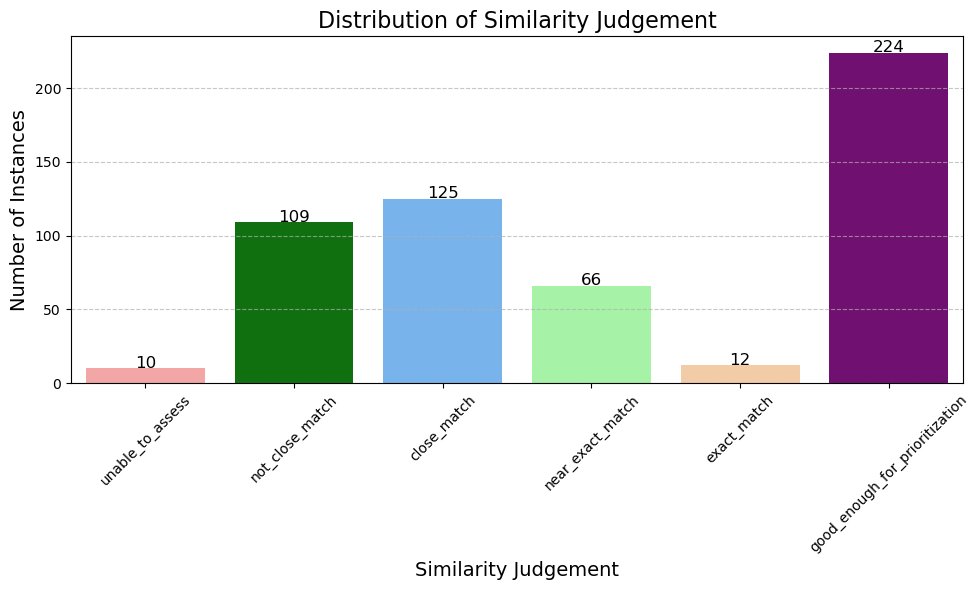

In [47]:
class_counts = df[['unable_to_assess', 'not_close_match','close_match', 'near_exact_match','exact_match', 'good_enough_for_prioritization']].sum()

# Define colors for each class
colors = ['#FF9999', 'green', '#66B3FF', '#99FF99', '#FFCC99', 'purple'] # Customize colors as needed

# Create a bar plot to visualize class imbalance
plt.figure(figsize=(10,6))
sns.barplot(x=class_counts.index, y=class_counts.values, palette=colors)
plt.title('Distribution of Similarity Judgement', fontsize=16)
plt.xlabel('Similarity Judgement', fontsize=14)
plt.ylabel('Number of Instances', fontsize=14)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value annotations on top of the bars
for index, value in enumerate(class_counts.values):
    plt.text(index, value + 0.5, str(value), ha='center', fontsize=12)

# Show the plot
plt.tight_layout()
plt.show()

In [37]:
# print ['unable_to_assess','close_match', 'near_exact_match','exact_match', 'good_enough_for_prioritization'] in df
# df[['unable_to_assess', 'close_match', 'near_exact_match', 'exact_match', 'good_enough_for_prioritization']]
# calculate how many times tehre are multiple positive labels in a single row
df['multiple_positive_labels'] = df[['unable_to_assess', 'close_match', 'not_close_match', 'near_exact_match', 'exact_match', 'good_enough_for_prioritization']].sum(axis=1) > 1
print(f"There are {df['multiple_positive_labels'].sum()} rows with multiple labels (with good_enough_for_prioritization included)")

df['multiple_positive_labels'] = df[['unable_to_assess', 'close_match', 'not_close_match', 'near_exact_match', 'exact_match']].sum(axis=1) > 1
print(f"There are {df['multiple_positive_labels'].sum()} rows with multiple labels (without good_enough_for_prioritization included)")

df['multiple_positive_labels'] = df[['unable_to_assess', 'close_match', 'not_close_match', 'near_exact_match', 'exact_match']].sum(axis=1) == 0
print(f"There are {df['multiple_positive_labels'].sum()} rows without labels (without good_enough_for_prioritization included)")


There are 174 rows with multiple labels (with good_enough_for_prioritization included)
There are 0 rows with multiple labels (without good_enough_for_prioritization included)
There are 114 rows without labels (without good_enough_for_prioritization included)


In [51]:
# remove rows with positive 'unable_to_assess' label
df = df[df['unable_to_assess']==0]
print(f"Removed rows with positive 'unable_to_assess' label. New shape: {df.shape}")
# remove rows with multiple positive labels
df['multiple_positive_labels'] = df[['close_match', 'not_close_match', 'near_exact_match', 'exact_match']].sum(axis=1) == 0
print(f"There are {df['multiple_positive_labels'].sum()} rows without labels (without good_enough_for_prioritization included)")
df = df[df['multiple_positive_labels']==False]
print(f"Removed rows with multiple positive labels. New shape: {df.shape}")


Removed rows with positive 'unable_to_assess' label. New shape: (426, 30)
There are 114 rows without labels (without good_enough_for_prioritization included)
Removed rows with multiple positive labels. New shape: (312, 31)


In [52]:
df

,ground_truth_smiles,predicted_smiles,ground_truth_inchikey14,predicted_inchikey14,ground_truth_formula,predicted_formula,annotator_name,unable_to_assess,not_close_match,close_match,...,predicted_embeddings,ground_truth_mol,predicted_mol,ground_truth_ECFP,predicted_ECFP,predicted_grover_fp,ground_truth_grover_fp,ground_truth_graph_emb,predicted_graph_emb,multiple_positive_labels
1,C1=CCC(C2OCC3(CO2)COC(C2CC=CCC2)OC3)CC1,C3=CCC(COCC2COC(C1CC=CCC1)OC2)CC3O,"[[WKTJXDHLMJKSGI, WKTJXDHLMJKSGI, WKTJXDHLMJKS...","[[JTVMBSVKCRWUHT, JTVMBSVKCRWUHT, JTVMBSVKCRWU...","[[C19H28O4, C19H28O4, C19H28O4, C19H28O4]]","[[C18H28O4, C18H28O4, C18H28O4, C18H28O4]]","[[0, 1, 2, 4]]",0,0,1,...,"[[1.2132535, -0.41205066, 0.35450518, 0.049653...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[0.5647918, 0.25824, 0.26585, 0.22250366, -1.3...","[1.2132535, -0.41205066, 0.35450518, 0.0496538...",False
3,C=C(C)C(CCC(C)(OC1OC(COC(C)=O)C(O)C1O)C1CCC2(C...,C=C(C)C(O)CCC(C)(O)C1CCC4(C)C1C(OC2OCC(O)C(O)C...,"[[JZASRXZWIPRQHB, JZASRXZWIPRQHB, JZASRXZWIPRQ...","[[SYJANXXYMFAOTM, SYJANXXYMFAOTM, SYJANXXYMFAO...","[[C37H60O11, C37H60O11, C37H60O11, C37H60O11]]","[[C35H58O9, C35H58O9, C35H58O9, C35H58O9]]","[[0, 1, 3, 4]]",0,0,1,...,"[[1.1534278, -0.4241, 0.29967058, 0.31541312, ...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[0.47095516, -0.14744547, 0.4086095, 0.6038899...","[1.1534278, -0.4241, 0.29967058, 0.31541312, -...",False
7,C=C(C)C(O)CCC(C)(O)C1CCC2(C)C1C(O)CC1C3(C)CCC(...,CC(C)CCCC(C)(O)C1CCC2(C)C1C(O)CC1C3(C)CCC(O)C(...,"[[CZGYKNXFDCANHD, CZGYKNXFDCANHD, CZGYKNXFDCAN...","[[MCOQJESQAGTIKS, MCOQJESQAGTIKS, MCOQJESQAGTI...","[[C30H52O4, C30H52O4, C30H52O4, C30H52O4]]","[[C30H54O3, C30H54O3, C30H54O3, C30H54O3]]","[[0, 3, 1, 4]]",0,0,0,...,"[[0.75288343, -0.44301885, 0.17056462, 0.05008...","[0.62723744, -0.52246565, 0.07977009, -0.05062...","[0.75288343, -0.44301885, 0.17056462, 0.050088...","[0.62723744, -0.52246565, 0.07977009, -0.05062...","[0.75288343, -0.44301885, 0.17056462, 0.050088...","[0.75288343, -0.44301885, 0.17056462, 0.050088...","[0.62723744, -0.52246565, 0.07977009, -0.05062...","[0.62723744, -0.52246565, 0.07977009, -0.05062...","[0.75288343, -0.44301885, 0.17056462, 0.050088...",False
8,C=C(C)C1CCC2(C(=O)O)CCC3(C)C(CCC4C5(C)C(C(=O)O...,CC5CCC4(C(=O)O)CCC3(C)C(=CCC2C1(C)CC(O)C(O)C(C...,"[[KEOMUCDXLJWLQT, KEOMUCDXLJWLQT, KEOMUCDXLJWL...","[[YCOKATFNRPZIIU, YCOKATFNRPZIIU, YCOKATFNRPZI...","[[C30H46O6, C30H46O6, C30H46O6, C30H46O6]]","[[C30H48O6, C30H48O6, C30H48O6, C30H48O6]]","[[1, 4, 3, 7]]",0,1,0,...,"[[1.1315619, -0.27097705, 0.45420912, -0.05245...","[0.123607725, -0.12065306, 0.26794386, 0.30156...","[1.1315619, -0.27097705, 0.45420912, -0.052451...","[0.123607725, -0.12065306, 0.26794386, 0.30156...","[1.1315619, -0.27097705, 0.45420912, -0.052451...","[1.1315619, -0.27097705, 0.45420912, -0.052451...","[0.123607725, -0.12065306, 0.26794386, 0.30156...","[0.123607725, -0.12065306, 0.26794386, 0.30156...","[1.1315619, -0.27097705, 0.45420912, -0.052451...",False
9,C=C(C)c1c(O)c(Br)c(C)c(O)c1Br,CC=C(Br)C(=O)C(C(C)C)=CBr,"[[VBECGTOARBMIBZ, VBECGTOARBMIBZ, VBECGTOARBMI...","[[DOYNKULNXPWLNV, DOYNKULNXPWLNV, DOYNKULNXPWL...","[[C10H10Br2O2, C10H10Br2O2, C10H10Br2O2]]","[[C9H12Br2O, C9H12Br2O, C9H12Br2O]]","[[2, 3, 4]]",0,1,0,...,"[[0.91796064, 0.31438163, 0.92296934, 0.355237...","[0.50251895, 0.04817588, 1.4725788, 0.5028914,...","[0.91796064, 0.31438163, 0.92296934, 0.3552372...","[0.50251895, 0.04817588, 1

# Saving train-validation splits for reuse later
## Validation set at 20% of original data

In [53]:
train_df, valid_df = train_test_split(df, test_size=0.2, random_state=CONFIG['seed'])

In [54]:
train_df['ground_truth_embeddings'].iloc[0].shape

(1, 768)

# Further feature extraction (ECFP, GROVER, Graph)

In [ ]:
from dataset import smiles_to_fingerprint

train_df['ground_truth_fp'] = train_df['ground_truth_smiles'].apply(smiles_to_fingerprint)
train_df['predicted_fp'] = train_df['predicted_smiles'].apply(smiles_to_fingerprint)

valid_df['ground_truth_fp'] = valid_df['ground_truth_smiles'].apply(smiles_to_fingerprint)
valid_df['predicted_fp'] = valid_df['predicted_smiles'].apply(smiles_to_fingerprint)


In [ ]:
from dataset import ecfp_embeddings

train_df = ecfp_embeddings(train_df)
valid_df = ecfp_embeddings(valid_df)

In [ ]:
from dataset import find_grover_fp
import numpy as np
grover_fp = np.load('../data/fp_large_unique_smiles.npz', allow_pickle=True)
train_df['ground_truth_grover_fp'] = train_df['ground_truth_smiles'].apply(lambda x: find_grover_fp(x))
train_df['predicted_grover_fp'] = train_df['predicted_smiles'].apply(lambda x: find_grover_fp(x))

valid_df['ground_truth_grover_fp'] = valid_df['ground_truth_smiles'].apply(lambda x: find_grover_fp(x))
valid_df['predicted_grover_fp'] = valid_df['predicted_smiles'].apply(lambda x: find_grover_fp(x))


In [ ]:
from dataset import prepare_datalist

train_df['ground_truth_graph_emb'] = prepare_datalist(train_df['ground_truth_smiles'])
train_df['predicted_graph_emb'] = prepare_datalist(train_df['predicted_smiles'])

valid_df['ground_truth_graph_emb'] = prepare_datalist(valid_df['ground_truth_smiles'])
valid_df['predicted_graph_emb'] = prepare_datalist(valid_df['predicted_smiles'])

## Saving train and validation splits for later reuse

In [41]:
# save the dataframes as pickle files
train_df.to_pickle('../data/train_split_remove_duplicates_all_embeddings.pkl')
valid_df.to_pickle('../data/valid_split_remove_duplicates_all_embeddings.pkl')
